In [5]:
import pandas as pd
import numpy as np
import sys
from pathlib import Path
sys.path.insert(0, str(Path("..").resolve()))
import eda
import eda_distance

In [6]:
n_obj = 3
n_items = 50
n_selected = 12
rho = 0.3
exactly = True
# choose problems or problems_with_empty_items
data = np.load(f'problems/items_{n_obj}obj_{n_items}items_{rho}rho_allneg_1200seed.npz')
items = data['items']
capacity = data['capacity']

3 obj 50 items: aspiration = np.array([5837, 6197, 4288])

5 obj 100 items: aspiration = np.array([14582, 11126,  7081,  9801,  8849])

9 obj 100 items: aspiration = np.array([11464,  9592, 10612,  7193,  8549, 10415, 11176, 10386, 12909])

In [ ]:
print(np.max(items[:, :n_obj] * n_selected, axis=0))
print(np.min(items[:, :n_obj] * n_selected, axis=0))
print(np.median(items[:, :n_obj] * n_selected, axis=0))

In [10]:
aspiration = np.array([11464,  9592, 10612,  7193,  8549, 10415, 11176, 10386, 12909])
hg_eda_run = eda_distance.KnapsackEDA(
    items=items,
    capacity=capacity,
    n_selected=n_selected,
    n_obj=n_obj,
    pop_size=1000,
    generations=200,
    max_no_improve_gen=3,
    max_row_diff=0.1,
    seed=1123,
    aspi=aspiration, 
    if_rank=True, 
    temp=0.1
)
results = hg_eda_run.run()
pf_eda = results["converged_pf_table"][-1]
ps_eda = results["converged_pf_population_table"][-1]
folder = "exact" if exactly else "upper_bound"
subfolder = "prefer" if aspiration is not None else "no_prefer"
np.savez(f"results/{folder}/{subfolder}/eda_{n_obj}obj_{n_items}items_{rho}rho_allneg.npz", F=pf_eda, X=ps_eda)

EDA finished in 36.87s (mode 1: 11 gens, mode 2: 12 gens)


In [7]:
aspiration = None
eda_run = eda.KnapsackEDA(
    items=items,
    capacity=capacity,
    n_selected=n_selected,
    n_obj=n_obj,
    pop_size=1000,
    generations=200,
    max_no_improve_gen=3,
    max_row_diff=0.1,
    seed=1123,
)
results = eda_run.run()
# pf_eda = results["converged_pf_table"][-1]
# ps_eda = results["converged_pf_population_table"][-1]
# folder = "exact" if exactly else "upper_bound"
# subfolder = "prefer" if aspiration is not None else "no_prefer"
# np.savez(f"results/{folder}/{subfolder}/eda_{n_obj}obj_{n_items}items_{rho}rho_allneg.npz", F=pf_eda, X=ps_eda)

import pickle
folder = "dist"
with open(f"results/{folder}/eda_{n_obj}obj_{n_items}items_{rho}rho_allneg_1200seed.pkl", "wb") as f:
    pickle.dump(results, f)

Mode 1 generation 1 (no improve count: 0)
Mode 1 generation 2 (no improve count: 0)
Mode 1 generation 3 (no improve count: 0)
Mode 1 generation 4 (no improve count: 0)
Mode 1 generation 5 (no improve count: 0)
Mode 1 generation 6 (no improve count: 0)
Mode 1 generation 7 (no improve count: 1)
Mode 1 generation 8 (no improve count: 0)
Mode 1 generation 9 (no improve count: 0)
Mode 1 generation 10 (no improve count: 1)
Mode 1 generation 11 (no improve count: 2)
Mode 2 generation 1 (no improve count: 0)
Mode 2 generation 2 (no improve count: 0)
Mode 2 generation 3 (no improve count: 0)
Mode 2 generation 4 (no improve count: 0)
Mode 2 generation 5 (no improve count: 0)
Mode 2 generation 6 (no improve count: 0)
Mode 2 generation 7 (no improve count: 0)
Mode 2 generation 8 (no improve count: 0)
Mode 2 generation 9 (no improve count: 0)
Mode 2 generation 10 (no improve count: 0)
Mode 2 generation 11 (no improve count: 0)
Mode 2 generation 12 (no improve count: 0)
Mode 2 generation 13 (no impr

In [20]:
# pf_exact = np.load(f"results/exact/exact_front_{n_obj}obj_{n_items}items_{rho}rho_allneg.npz")["F"]
# pf_ks = np.load(f"results/exact/KS_{n_obj}obj_{n_items}items_{rho}rho_allneg.npz")["pf"]
pf_eda = np.load(f"results/exact/no_prefer/eda_{n_obj}obj_{n_items}items_{rho}rho_allneg.npz")["F"]
pf_nsga2 = np.load(f"results/exact/no_prefer/nsga2_{n_obj}obj_{n_items}items_{rho}rho_allneg.npz")["F"]
pf_nsga3 = np.load(f"results/exact/no_prefer/nsga3_{n_obj}obj_{n_items}items_{rho}rho_allneg.npz")["F"]
pf_spea2 = np.load(f"results/exact/no_prefer/spea2_{n_obj}obj_{n_items}items_{rho}rho_allneg.npz")["F"]
ps_eda = np.load(f"results/exact/no_prefer/eda_{n_obj}obj_{n_items}items_{rho}rho_allneg.npz")["X"]
ps_nsga2 = np.load(f"results/exact/no_prefer/nsga2_{n_obj}obj_{n_items}items_{rho}rho_allneg.npz")["X"]
ps_nsga3 = np.load(f"results/exact/no_prefer/nsga3_{n_obj}obj_{n_items}items_{rho}rho_allneg.npz")["X"]
ps_spea2 = np.load(f"results/exact/no_prefer/spea2_{n_obj}obj_{n_items}items_{rho}rho_allneg.npz")["X"]

In [ ]:
# pf_exact = np.load(f"results/upper_bound/exact_front_{n_obj}obj_{n_items}items_{rho}rho_allneg.npz")["F"]
# pf_ks = np.load(f"results/upper_bound/KS_{n_obj}obj_{n_items}items_{rho}rho_allneg.npz")["pf"]
pf_eda = np.load(f"results/upper_bound/eda_{n_obj}obj_{n_items}items_{rho}rho_allneg.npz")["F"]
pf_nsga2 = np.load(f"results/upper_bound/nsga2_{n_obj}obj_{n_items}items_{rho}rho_allneg.npz")["F"]
pf_nsga3 = np.load(f"results/upper_bound/nsga3_{n_obj}obj_{n_items}items_{rho}rho_allneg.npz")["F"]
pf_spea2 = np.load(f"results/upper_bound/spea2_{n_obj}obj_{n_items}items_{rho}rho_allneg.npz")["F"]
ps_eda = np.load(f"results/upper_bound/eda_{n_obj}obj_{n_items}items_{rho}rho_allneg.npz")["X"]
ps_nsga2 = np.load(f"results/upper_bound/nsga2_{n_obj}obj_{n_items}items_{rho}rho_allneg.npz")["X"]
ps_nsga3 = np.load(f"results/upper_bound/nsga3_{n_obj}obj_{n_items}items_{rho}rho_allneg.npz")["X"]
ps_spea2 = np.load(f"results/upper_bound/spea2_{n_obj}obj_{n_items}items_{rho}rho_allneg.npz")["X"]

In [14]:
pf_hg_eda = np.load(f"results/exact/prefer/eda_{n_obj}obj_{n_items}items_{rho}rho_allneg.npz")["F"]
ps_hg_eda = np.load(f"results/exact/prefer/eda_{n_obj}obj_{n_items}items_{rho}rho_allneg.npz")["X"]
pf_hg_rnsga2 = np.load(f"results/exact/prefer/rnsga2_{n_obj}obj_{n_items}items_{rho}rho_allneg.npz")["F"]
ps_hg_rnsga2 = np.load(f"results/exact/prefer/rnsga2_{n_obj}obj_{n_items}items_{rho}rho_allneg.npz")["X"]
pf_hg_rnsga3 = np.load(f"results/exact/prefer/rnsga3_{n_obj}obj_{n_items}items_{rho}rho_allneg.npz")["F"]
ps_hg_rnsga3 = np.load(f"results/exact/prefer/rnsga3_{n_obj}obj_{n_items}items_{rho}rho_allneg.npz")["X"]

In [12]:
# print(pf_exact.shape)
# print(pf_ks.shape)
print(pf_eda.shape)
print(pf_nsga2.shape)
print(pf_nsga3.shape)
print(pf_spea2.shape)

(12854, 9)
(1000, 9)
(1000, 9)
(1000, 9)


In [ ]:
print(pf_hg_eda.shape)
print(pf_hg_rnsga2.shape)
print(pf_hg_rnsga3.shape)

In [ ]:
np.allclose(
    np.unique(np.round(pf_nsga3), axis=0),
    np.unique(np.round(pf_ks), axis=0),
)

In [ ]:
pf_eda_pd = pd.read_csv("../card_game/eda_results/pf_trial0.csv", header=None)
pf_eda = np.array(pf_eda_pd)
pf_eda = np.load("problems/pf_1_eda.npz")["arr_0"]
pf_KirlikSayin_no_constraint = np.load("problems/pf_1_no_constraint.npz")["pf"]
pf_KirlikSayin = np.load("problems/pf_1.npz")["pf"]
pf_TV = np.load("problems/pf_1_TV.npz")["pf"]

In [ ]:
pf_eda.shape

In [ ]:
pf_KirlikSayin.shape

In [ ]:
pf_TV.shape

In [ ]:
np.allclose(pf_KirlikSayin, pf_KirlikSayin_no_constraint)

In [ ]:
def rows_not_in(a, b, atol=1e-8, rtol=1e-5):
    """Rows of `a` that do not appear (approx.) in `b`."""
    mask = np.ones(len(a), dtype=bool)
    for i, row in enumerate(a):
        if np.any(np.all(np.isclose(b, row, atol=atol, rtol=rtol), axis=1)):
            mask[i] = False
    return a[mask], np.where(mask)[0]
missing, idx = rows_not_in(pf_eda[:, :n_obj], pf_KirlikSayin)
print(idx)      # indices into pf_eda
print(missing)

In [ ]:
missing, idx = rows_not_in(pf_TV, pf_KirlikSayin)
print(idx)     
print(missing)

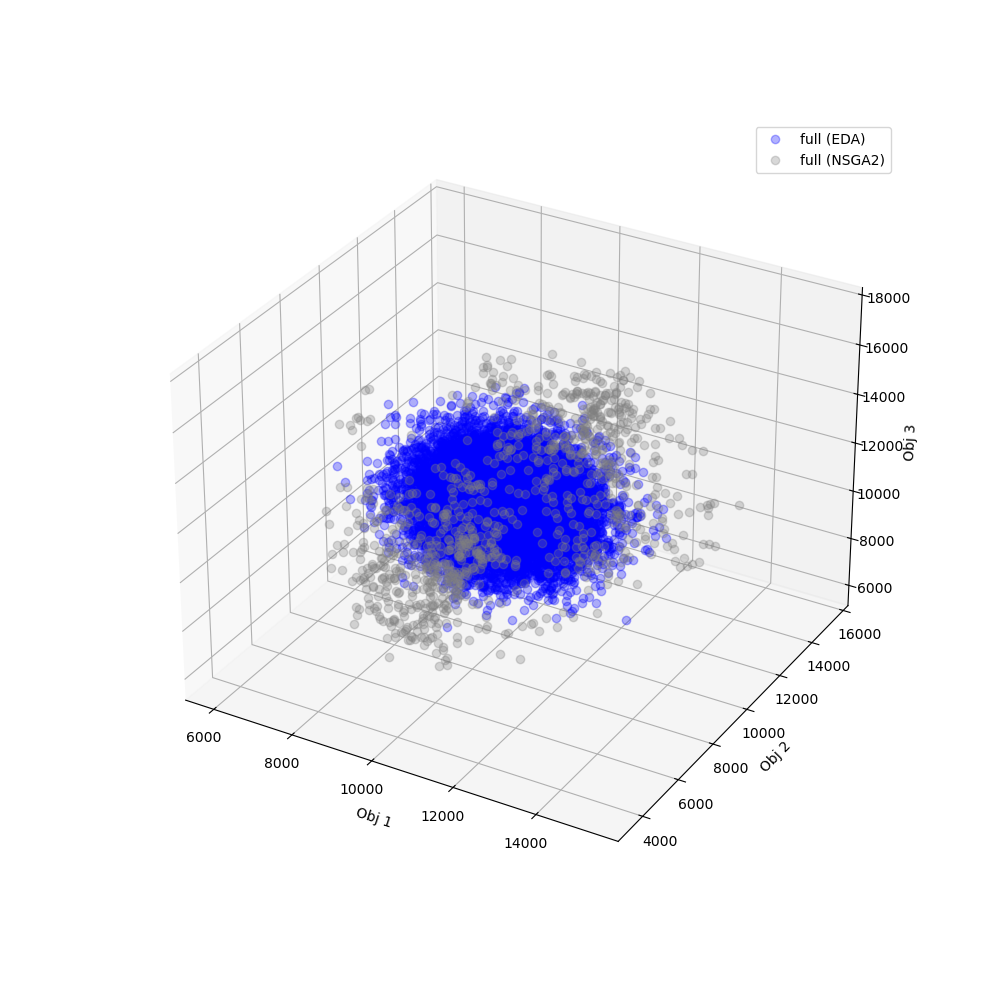

In [ ]:
import matplotlib.pyplot as plt
%matplotlib widget
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(projection='3d')
ax.plot(pf_nsga2[:,0], pf_nsga2[:,1], pf_nsga2[:,2], 'o', color='gray', alpha=0.3, markersize=6, label="full (NSGA2)")
ax.plot(pf_eda[:,0], pf_eda[:,1], pf_eda[:,2], 'o', color='blue', alpha=0.3, markersize=6, label="full (EDA)")
ax.plot(pf_nsga2[:,0], pf_nsga2[:,1], pf_nsga2[:,2], 'o', color='gray', alpha=0.3, markersize=6, label="full (NSGA2)")
# ax.plot(pf_hg_eda[:,0], pf_hg_eda[:,1], pf_hg_eda[:,2], 'bo', alpha=0.5, markersize=6, label="HG-EDA")
# ax.plot(pf_hg_rnsga3[:,0], pf_hg_rnsga3[:,1], pf_hg_rnsga3[:,2], 'go', alpha=0.5, markersize=6, label="RNSGA3")
# ax.plot(aspiration[0], aspiration[1], aspiration[2], 'rs', alpha=0.5, markersize=6, label="Aspiration")
# ax.plot(pf_nsga2[300,0], pf_nsga2[300,1], pf_nsga2[300,2], 'rs', alpha=0.5, markersize=6, label="Aspiration")
ax.set_xlabel('Obj 1')
ax.set_ylabel('Obj 2')
ax.set_zlabel('Obj 3')
ax.legend()
plt.show()

In [ ]:
from pymoo.indicators.hv import HV

ref_point = np.zeros(n_obj)
hv = HV(ref_point=ref_point)
hv_pf_1 = hv(-pf_eda)
hv_pf_2 = hv(-pf_nsga2)
print(hv_pf_1)
print(hv_pf_2)

In [ ]:
def calculate_dominated(pf_predicted, pf_actual, n_obj):
    dominated = np.zeros(len(pf_predicted))
    for i in range(len(pf_predicted)):
        for j in range(len(pf_actual)):
            if np.all(pf_actual[j, :n_obj] >= pf_predicted[i, :n_obj]) and \
                np.any(pf_actual[j, :n_obj] > pf_predicted[i, :n_obj]):
                dominated[i] = 1
                break
    return np.sum(dominated), np.sum(dominated)/len(pf_predicted)

num_dominated, ratio_dominated = calculate_dominated(pf_hg_eda, pf_hg_rnsga2, 3)
print(ratio_dominated)
num_dominated, ratio_dominated = calculate_dominated(pf_hg_rnsga2, pf_hg_eda, 3)
print(ratio_dominated)